### Loading Data

In [1]:
import pandas as pd

patient_info = pd.read_csv("drug200.csv")

print(patient_info.shape)
print(patient_info.isnull().sum())
patient_info["Drug"].value_counts()

(200, 6)
Age            0
Sex            0
BP             0
Cholesterol    0
Na_to_K        0
Drug           0
dtype: int64


Drug
DrugY    84
drugX    60
drugA    23
drugB    20
drugC    13
Name: count, dtype: int64

**Note:** The dataset has 200 patient records and 6 columns, with no missing values. The classes are imbalanced: DrugY is the most common (84 records) and drugC the least common (13 records). This matters later because a model can look accurate while performing poorly on the rare classes.

### ENCODING

In [2]:
X = pd.get_dummies(patient_info.drop(columns="Drug"), dtype=int)
y = patient_info["Drug"]

print(X.columns.tolist())
X.head()

['Age', 'Na_to_K', 'Sex_F', 'Sex_M', 'BP_HIGH', 'BP_LOW', 'BP_NORMAL', 'Cholesterol_HIGH', 'Cholesterol_NORMAL']


,Age,Na_to_K,Sex_F,Sex_M,BP_HIGH,BP_LOW,BP_NORMAL,Cholesterol_HIGH,Cholesterol_NORMAL
0,20,26.130,1,0,0,0,1,0,1
1,61,8.959,0,1,0,0,1,0,1
2,54,13.943,1,0,1,0,0,0,1
3,41,31.748,0,1,0,0,1,1,0
4,40,7.296,1,0,0,1,0,0,1


**Note:** `Drug` is the target the model will predict, and the other five columns are the features. The categorical columns (`Sex`, `BP`, `Cholesterol`) were converted into 0/1 columns with one-hot encoding, giving 9 numeric features. The target was removed from the features so the model cannot see the answer.

### Split into training and test sets

In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)
print(y_train.value_counts())
print(y_test.value_counts())

(160, 9) (40, 9)
Drug
DrugY    67
drugX    48
drugA    19
drugB    16
drugC    10
Name: count, dtype: int64
Drug
DrugY    17
drugX    12
drugB     4
drugA     4
drugC     3
Name: count, dtype: int64


**Note:** The data was split 80/20 into 160 training and 40 test records, stratified by drug and with `random_state=42` so the split is reproducible. The test set is not used until evaluation. With only 3 drugC records in the test set, results for that class are very sensitive to a single error.

### Train a baseline and a Random Forest

In [4]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

tree_model = DecisionTreeClassifier(random_state=42)
tree_model.fit(X_train, y_train)

forest_model = RandomForestClassifier(n_estimators=100, random_state=42)
forest_model.fit(X_train, y_train)

for name, model in [("Decision Tree", tree_model), ("Random Forest", forest_model)]:
    train_acc = accuracy_score(y_train, model.predict(X_train))
    test_acc = accuracy_score(y_test, model.predict(X_test))
    print(f"{name}: train = {train_acc:.3f}, test = {test_acc:.3f}")

Decision Tree: train = 1.000, test = 1.000
Random Forest: train = 1.000, test = 1.000


**Note:** A Decision Tree and a Random Forest (100 trees) were trained on the 160 training records and scored on the 40 test records. Both models scored 1.00 on the training set and 1.00 on the test set. Scores this high are expected, because the drug labels in this synthetic dataset follow fixed rules that tree-based models can recover easily. They do not indicate clinical usefulness.

### Evaluate the Random Forest on the test set

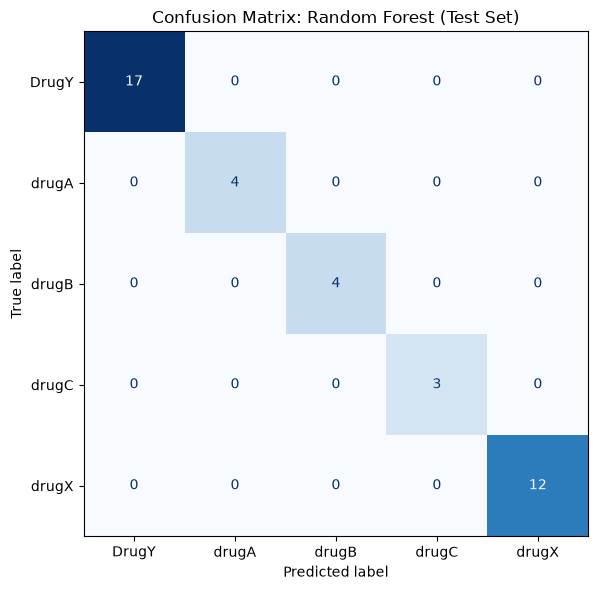

              precision    recall  f1-score   support

       DrugY       1.00      1.00      1.00        17
       drugA       1.00      1.00      1.00         4
       drugB       1.00      1.00      1.00         4
       drugC       1.00      1.00      1.00         3
       drugX       1.00      1.00      1.00        12

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40



In [5]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

y_pred = forest_model.predict(X_test)

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, ax=ax, cmap="Blues", colorbar=False
)
ax.set_title("Confusion Matrix: Random Forest (Test Set)")
plt.tight_layout()
plt.savefig("images/confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

print(classification_report(y_test, y_pred))

**Note:** The confusion matrix shows all 40 test records on the diagonal, so the model made no misclassifications. Precision and recall are 1.00 for every drug. This is consistent with the synthetic, rule-based labels, and it should not be expected on real prescribing data. The small test counts for drugA, drugB, and drugC (4, 4, and 3 records) mean this evaluation says little about how the model would handle rare classes.

### Which features does the model rely on?

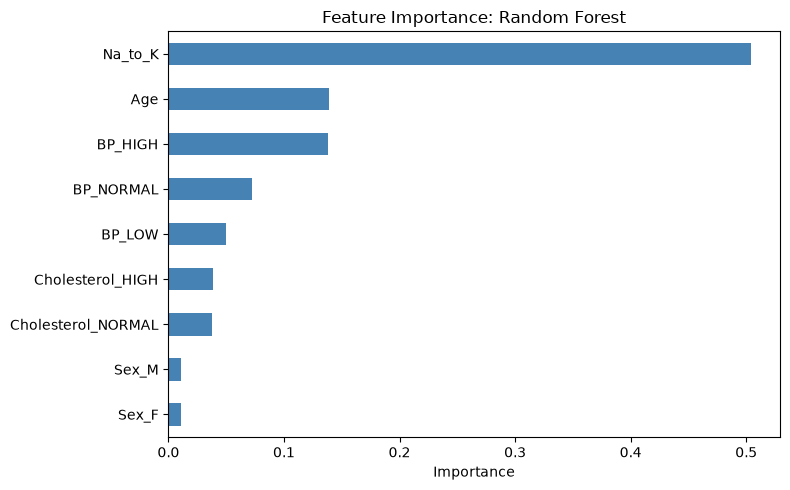

Na_to_K               0.504
Age                   0.139
BP_HIGH               0.138
BP_NORMAL             0.072
BP_LOW                0.050
Cholesterol_HIGH      0.038
Cholesterol_NORMAL    0.038
Sex_M                 0.011
Sex_F                 0.010
dtype: float64

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

importance = pd.Series(forest_model.feature_importances_, index=X.columns)
importance = importance.sort_values()

plt.figure(figsize=(8, 5))
importance.plot(kind="barh", color="steelblue")
plt.title("Feature Importance: Random Forest")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig("images/feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

importance.sort_values(ascending=False).round(3)

**Note:** Na_to_K was the most important feature (about 0.50), followed by Age (0.14) and BP_HIGH (0.14), while Sex contributed almost nothing (about 0.01 per column). This agrees with the Week 1 exploration and with how the synthetic labels were generated, where Na_to_K and BP drive most of the drug assignments and Sex plays no role. Feature importance describes what this model uses on this dataset, and it does not show a clinical or causal relationship.

### How much depth does a decision tree need

In [8]:
results = []

for depth in [1, 2, 3, 4, 5]:
    model = DecisionTreeClassifier(max_depth=depth, random_state=42)
    model.fit(X_train, y_train)
    results.append({
        "max_depth": depth,
        "train_accuracy": accuracy_score(y_train, model.predict(X_train)),
        "test_accuracy": accuracy_score(y_test, model.predict(X_test)),
    })

depth_results = pd.DataFrame(results).round(3)
depth_results

,max_depth,train_accuracy,test_accuracy
0,1,0.719,0.725
1,2,0.838,0.825
2,3,0.938,0.925
3,4,1.000,1.000
4,5,1.000,1.000


**Note:** Test accuracy rose from 0.725 at depth 1 to 0.925 at depth 3 and reached 1.000 at depth 4, with no further gain at depth 5. Training and test accuracy stayed close at every depth, so the tree was not overfitting. The depth needed is consistent with the layered rules used to generate the labels. This result describes this synthetic dataset only.

### Check stability with 5-fold cross-validation

In [9]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
}

for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=cv)
    print(f"{name}: folds = {scores.round(3)}, mean = {scores.mean():.3f}, std = {scores.std():.3f}")

Decision Tree: folds = [1. 1. 1. 1. 1.], mean = 1.000, std = 0.000
Random Forest: folds = [1. 1. 1. 1. 1.], mean = 1.000, std = 0.000


**Note:** Both the Decision Tree and the Random Forest scored 1.000 on every one of the five stratified folds (mean 1.000, standard deviation 0.000). This shows the earlier result was not caused by one favorable train/test split. Because the labels follow fixed rules, perfect cross-validation scores are expected here and should not be assumed for real clinical data.

**Model choice:** The Decision Tree and Random Forest performed identically on this dataset. The Random Forest will be carried forward to Week 4 because it is generally more robust on noisy data, not because it scored higher here.